# Project 2 — Q5: Cell Matching × Segmentation

**NYU Tandon · CS-GY 6643 · Fall 2026**  
**Team member(s) / NetID(s):** To be added

A compact **traditional computer-vision** pipeline: background subtraction, Gaussian blob responses, Hessian shape filtering, marker-controlled watershed, correlation-based registration, RANSAC refinement and one-to-one assignment. No pretrained models, neural networks, manual masks, test labels or sample-specific prediction branches.

**Target: 0.70 combined score, not pixel accuracy.** Lecture 6 improvements use shape filtering, full affine search/refinement and mouse-grouped validation. The measured results below determine whether that target was reached. This notebook and `cell_matching.py` reproduce the candidate CSV; no Kaggle upload or official leaderboard score is claimed.

## Data, sources and validation

[Competition](https://www.kaggle.com/competitions/testingpj-2): user-downloaded data contains 47 training regions from three mice and 29 hidden-test regions, with 152 native 16-bit TIFFs, 14,893 in-vivo cells, 5,516 ex-vivo cells and 1,139 verified pairs. Local hashes and dimensions are in `DATA_SOURCES.json`. Original images are loaded unchanged; normalization applies only to derived processing arrays.

**Sources:** Q5 handout §§4–6; L3 RANSAC (pp. 27–52), L4 filtering/segmentation/warping (pp. 42–104), L5 segmentation and registration guidance (pp. 11–38, 111). RLE follows L5 codelab cell 18: zero-based, row-major `start length`, empty string for an empty mask. Released mask bounds and visual overlays agree with this convention. The complete pipeline is a project adaptation. In particular, the codelab's use of known correspondence pairs for registration is **not** used at prediction time.

The handout metric is `0.25 PQ_invivo + 0.25 PQ_exvivo + 0.50 F1_match`. Mask true positives require **IoU > 0.75**. PQ is averaged over regions; matching counts are pooled before computing F1. A match is correct only when both masks pass IoU and the pair is verified. Unverified pairs are not biological negatives, although unverified predictions receive no matching credit.

**Lecture 6 follow-up:** the supplied tips slide (p. 70) motivates filtering elongated masks, affine initialization, close-mutual-neighbor ICP, grouped cross-validation, overlays and Hungarian matching. Neural fine-tuning and loss functions are excluded by the user's traditional-only requirement.

The old 18-region holdout has already been inspected. New shape/gating choices use **leave-one-mouse-out selection**: choose using two mice and score the third, then pool out-of-fold matching counts. All three folds selected axis ratio ≤3 without an additional size cutoff beyond the existing area filter. Base detector settings and method design reflect earlier experiments, so this is **retrospective grouped development validation**, not a fresh unbiased test or a Kaggle score. The old fixed baseline on all 47 regions scored 0.1468 (PQ 0.3708/0.1981, F1 0.0092); this is a descriptive comparison, not an independent test of model selection. Final submission settings are selected using all released training regions after grouped evaluation.

**Live rules/scorer limitation:** Kaggle's unauthenticated data API returned HTTP 401. This is a local reconstruction of the supplied handout metric, not a verified copy of the official scorer. Empty/empty PQ and all-empty matching F1 are defined as 1 locally; those cases do not occur in the supplied labeled data.

In [1]:
from pathlib import Path
import json
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy import ndimage as ndi
from skimage.segmentation import mark_boundaries
from matplotlib.patches import ConnectionPatch
from cell_matching import (PARAMETERS, read_pair, normalize, predict_pair, decode_rle,
                           centers, evaluate, summarize, write_submission, segment, register, match_cells)

root = Path("Data")
out = Path("outputs/q5")
out.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(root / "training/train_ground_truth.csv", dtype=str)
sample = pd.read_csv(root / "sample_submission.csv", dtype=str)
assert list(train.columns) == list(sample.columns)
assert train.sample_id.is_unique and sample.sample_id.is_unique
held_out = train.sample_id.str.split("__").str[0] == "subject_db6b8b"
print(f"{len(train)} training regions, 3 mouse groups, {len(sample)} test regions")
PARAMETERS

47 training regions, 3 mouse groups, 29 test regions


{'invivo': {'sigma': 2.5,
  'threshold': 0.025,
  'fraction': 0.15,
  'dilation': 1,
  'max_elongation': 3},
 'exvivo': {'sigma': 3,
  'threshold': 0.12,
  'fraction': 0.15,
  'blobness': 0.6,
  'max_elongation': 3},
 'matching': {'gate': 8, 'cutoff': 0.14}}

## 1. Instance segmentation

Normalize between intensity percentiles 1 and 99.8, subtract a broad Gaussian background, and find peaks of a difference-of-Gaussians response. The ex-vivo detector additionally uses Hessian curvature balance: round bright peaks curve in two directions, whereas a thin fiber mainly curves across its width. Grow separate regions with watershed, threshold each relative to its peak, bound growth to 12 pixels from a seed and reject areas outside 25–350 pixels. Reject masks whose major/minor axis ratio exceeds 3, as suggested by Lecture 6. In-vivo regions expand by one pixel, which improved the overly tight initial boundaries on development images.

The same modality parameters apply to every region. Candidate threshold, smoothing, boundary, dilation, ellipse-fit and Hessian variants were compared; ellipse fitting and fixed global thresholds were weaker. Final selection gave development PQ approximately **0.347 in vivo / 0.178 ex vivo**. These are historical development results before the new shape filter, not current grouped or leaderboard scores. Missing dim cells, merged cells and bright processes remain limitations.

The helper file contains the full implementation; no prior notebook is executed or imported. The panels below compare an automatically centered training crop with its annotations. Crop selection is **display only** and does not influence prediction.

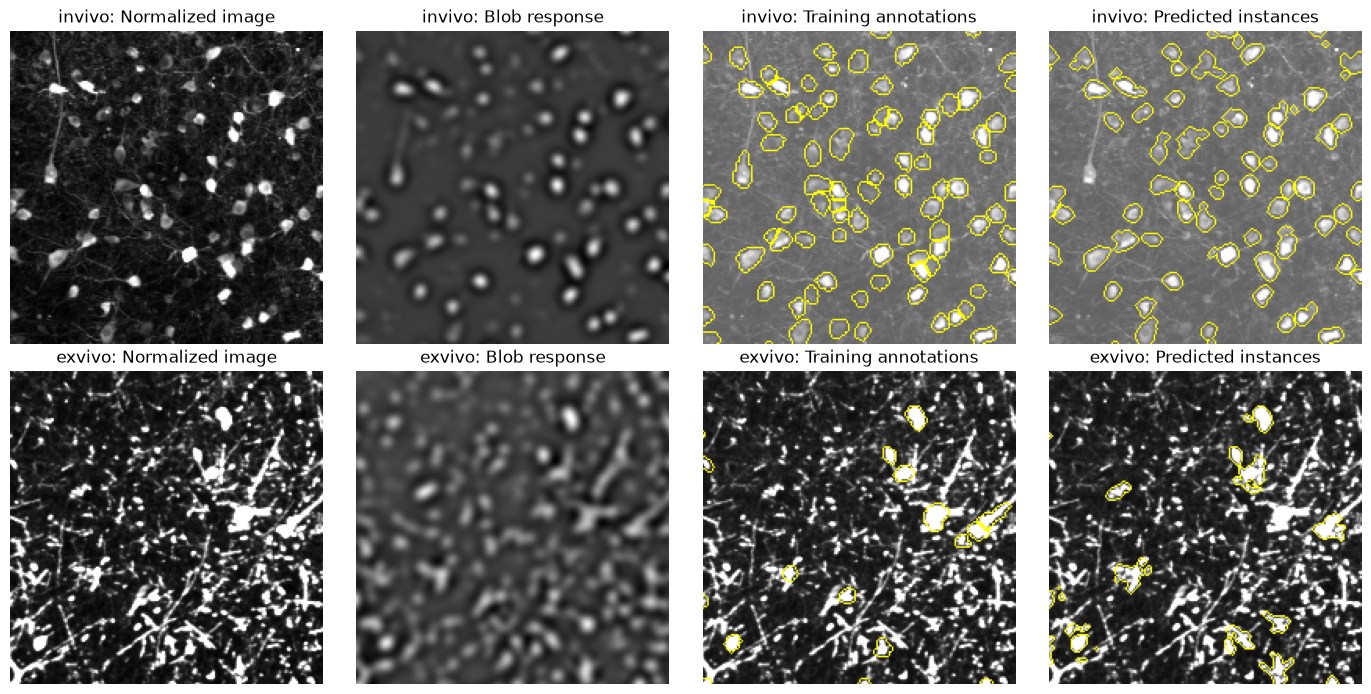

In [2]:
example = train.loc[~held_out].iloc[0]
images = read_pair(root / "training", example.sample_id)
labels, pairs, matrix, correlation = predict_pair(images)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, (image, prediction, modality) in enumerate(zip(images, labels, ["invivo", "exvivo"])):
    truth = np.zeros(image.shape, np.int32)
    for i, rle in enumerate(json.loads(example[modality + "_instances"]).values(), 1):
        truth[decode_rle(rle, image.shape)] = i
    y, x = np.median(np.argwhere(truth > 0), axis=0).astype(int)
    crop = np.s_[max(0, y-100):y+100, max(0, x-100):x+100]
    image_float = normalize(image)
    signal = np.maximum(ndi.gaussian_filter(image_float, 1) - ndi.gaussian_filter(image_float, 10), 0)
    sigma = PARAMETERS[modality]["sigma"]
    response = ndi.gaussian_filter(signal, sigma) - ndi.gaussian_filter(signal, 1.6*sigma)
    pictures = [image_float[crop], response[crop], mark_boundaries(image_float[crop], truth[crop]),
                mark_boundaries(image_float[crop], prediction[crop])]
    for ax, picture, title in zip(axes[row], pictures, ["Normalized image", "Blob response", "Training annotations", "Predicted instances"]):
        ax.imshow(picture, cmap="gray")
        ax.set_title(f"{modality}: {title}")
        ax.axis("off")
    tifffile.imwrite(out / f"example_{modality}_labels.tif", prediction.astype(np.uint16))
plt.tight_layout()
plt.savefig(out / "segmentation_diagnostics.png", dpi=150)
plt.show()

## 2. Lecture 6: affine search, ICP and one-to-one matching

A similarity transform cannot represent shear or unequal scaling. Search positive band-pass responses at 0.33 resolution over rotation (±20°), independent x/y scales (0.9–1.1 / 0.8–1.0), shear (−0.1, 0, 0.1) and all valid translations. Refine the best hypothesis locally. These are shared search bounds, not per-image transforms. Full-frame size ratios are **not** cell-scale estimates; transforms outside the search range remain a limitation.

Refine with up to five ICP iterations: find close mutual nearest predicted centroids, fit a **full affine** map with RANSAC, and reject reflected/ill-conditioned fits. Assign with Hungarian matching and dummy unmatched columns. Select the distance gate and minimum image-correlation score within mouse-grouped folds. Only image-derived detections enter prediction; annotated coordinates are used solely for training diagnostics/evaluation.

Correlation is a heuristic, not a probability. Some alignments remain wrong. The overlays below help reveal those failures rather than relying on a correspondence count alone.

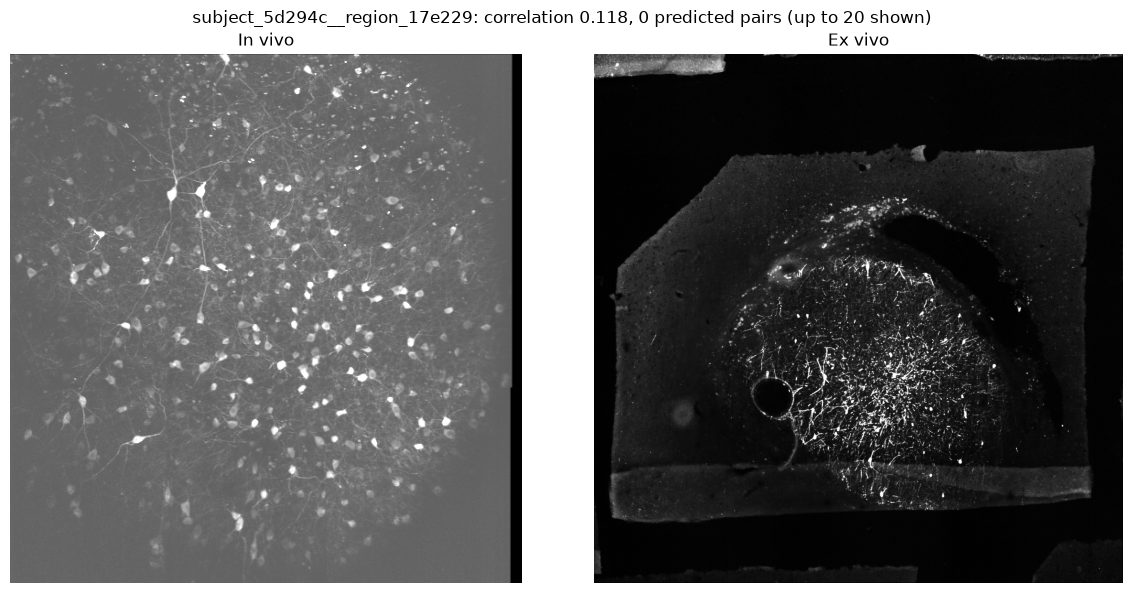

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, image, title in zip(axes, images, ["In vivo", "Ex vivo"]):
    ax.imshow(normalize(image), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
a, b = [centers(mask) for mask in labels]
for i, j in pairs[:20]:
    fig.add_artist(ConnectionPatch(a[i-1], b[j-1], "data", "data", axesA=axes[0], axesB=axes[1],
                                  color="lime", linewidth=.7, alpha=.7))
fig.suptitle(f"{example.sample_id}: correlation {correlation:.3f}, {len(pairs)} predicted pairs (up to 20 shown)")
plt.tight_layout()
plt.savefig(out / "matching_diagnostics.png", dpi=150)
plt.show()

## 3. Retrospective mouse-grouped validation

New shape filtering was compared across area and axis-ratio choices, selecting on two mice and evaluating the third; all folds preferred an axis ratio of 3. The code below repeats matching-gate selection with no labels from the scored mouse used to choose its gate/cutoff. Fixed base detector settings came from earlier development, so these results are not a new untouched estimate. PQ is averaged over all 47 out-of-fold regions; matching F1 pools their counts.

In [4]:
records = []
for row in train.itertuples(index=False):
    image_pair = read_pair(root / "training", row.sample_id)
    prediction = [segment(im, **PARAMETERS[m]) for im, m in zip(image_pair, ["invivo", "exvivo"])]
    transform, confidence = register(*image_pair)
    for gate in [4, 6, 8, 10]:
        predicted_pairs, _ = match_cells(*prediction, transform, gate)
        for cutoff in [.08, .10, .12, .14, .16]:
            accepted = predicted_pairs if confidence >= cutoff else []
            records.append(dict(sample_id=row.sample_id, subject=row.sample_id.split("__")[0],
                                gate=gate, cutoff=cutoff, correlation=confidence,
                                **evaluate(prediction, accepted, row)))
candidates = pd.DataFrame(records)
candidates.to_csv(out / "lecture6_matching_candidates.csv", index=False)
folds, choices = [], []
for subject in sorted(candidates.subject.unique()):
    development = candidates[candidates.subject != subject]
    options = [dict(gate=gate, cutoff=cutoff, **summarize(group))
               for (gate, cutoff), group in development.groupby(["gate", "cutoff"])]
    best = max(options, key=lambda option: option["score"])
    fold = candidates[(candidates.subject == subject) & (candidates.gate == best["gate"])
                      & (candidates.cutoff == best["cutoff"])]
    folds.append(fold)
    choices.append(dict(subject=subject, gate=best["gate"], cutoff=best["cutoff"], **summarize(fold)))
metrics = pd.concat(folds)
metrics.to_csv(out / "lecture6_cv_metrics.csv", index=False)
display(pd.DataFrame(choices).set_index("subject").round(4))
summary = summarize(metrics)
display(pd.DataFrame([summary], index=["Grouped development"]).round(4))
print(f"Combined score: {summary['score']:.4f}; target 0.7000 {'reached' if summary['score'] >= .7 else 'NOT reached'}")

,gate,cutoff,pq_invivo,pq_exvivo,f1_match,score
subject,,,,,,
subject_5d294c,8,0.14,0.3967,0.2026,0.0464,0.1730
subject_b2ba5e,10,0.14,0.2957,0.1520,0.0291,0.1265
subject_db6b8b,8,0.12,0.4119,0.2337,0.0499,0.1864


,pq_invivo,pq_exvivo,f1_match,score
Grouped development,0.3746,0.2005,0.0447,0.1661


Combined score: 0.1661; target 0.7000 NOT reached


### Warp overlays: inspect good and bad alignment hypotheses

The highest- and lowest-correlation training examples are selected automatically, not by ground-truth correctness. Red is warped in-vivo intensity; green is ex-vivo intensity. Yellow indicates coincident brightness, which alone does not prove a valid cell correspondence. The displayed crop is computed from the warped source footprint.

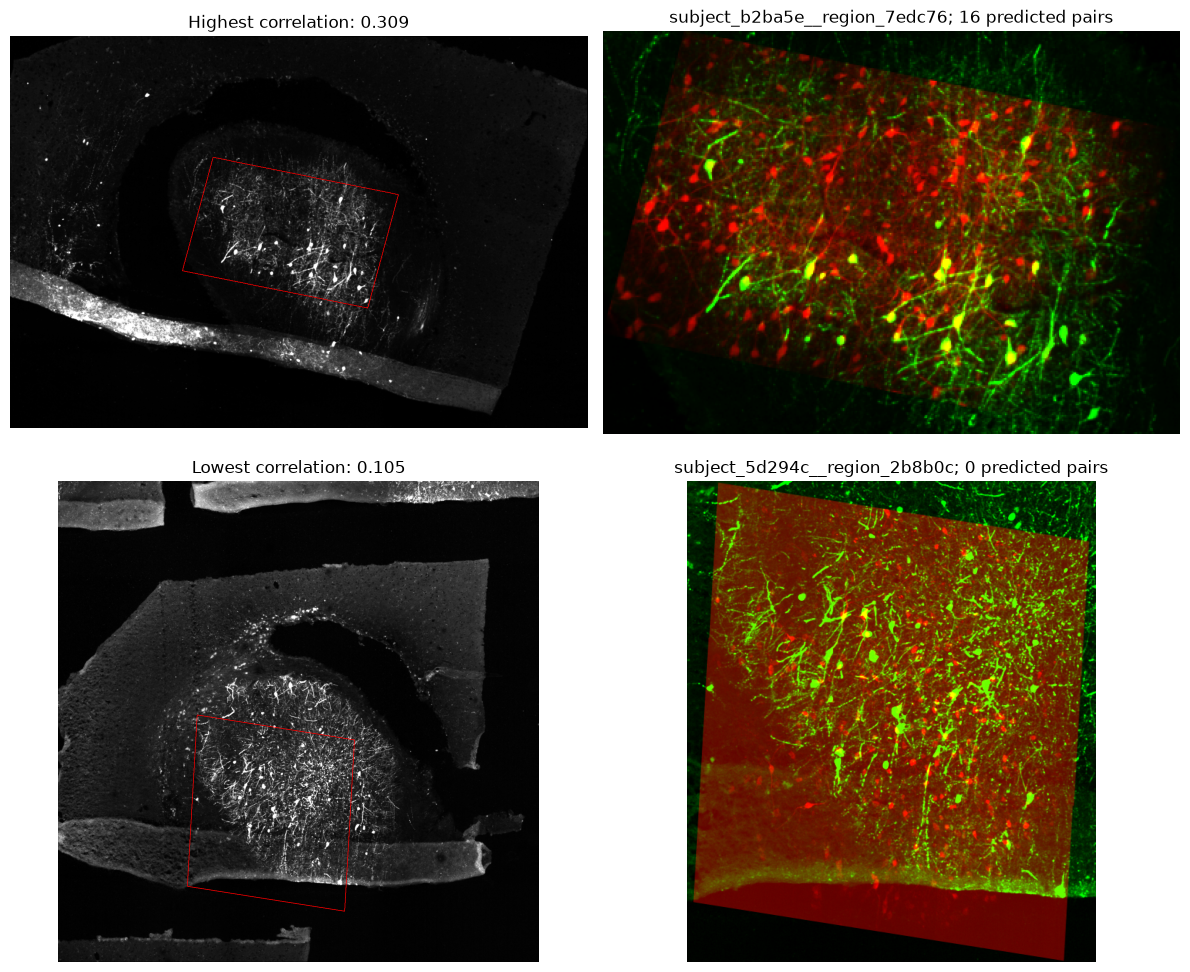

In [5]:
ranked = metrics.sort_values("correlation")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row_index, position in enumerate([-1, 0]):
    sample_id = ranked.iloc[position].sample_id
    image_pair = read_pair(root / "training", sample_id)
    _, matched, transform, confidence = predict_pair(image_pair)
    if transform is None:
        continue
    source, target = [normalize(im) for im in image_pair]
    h, w = target.shape
    warped = cv2.warpAffine(source, transform, (w, h))
    support = cv2.warpAffine(np.ones(source.shape, np.uint8), transform, (w, h)) > 0
    y, x = np.where(support)
    if not len(x):
        continue
    crop = np.s_[y.min():y.max()+1, x.min():x.max()+1]
    overlay = np.dstack([warped, target, np.zeros_like(target)])
    axes[row_index, 0].imshow(target, cmap="gray")
    axes[row_index, 0].contour(support, levels=[.5], colors="red", linewidths=.5)
    axes[row_index, 1].imshow(overlay[crop])
    axes[row_index, 0].set_title(f"{'Highest' if position == -1 else 'Lowest'} correlation: {confidence:.3f}")
    axes[row_index, 1].set_title(f"{sample_id}; {len(matched)} predicted pairs")
    for ax in axes[row_index]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(out / "alignment_overlays.png", dpi=150)
plt.show()

## 4. Generate and validate the candidate submission

Use the released sample IDs in their original order. Encode native-size masks as JSON RLE dictionaries and one-to-one ID pairs as JSON arrays. Check schema, exact sample coverage, nonempty mask bounds, encode/decode round trips, pair references, pair uniqueness and CSV round trips. All predicted masks are generated from each image; there are no hand-edited answers.

The following cell writes a **local candidate**, not a Kaggle submission. Reproduce it independently with:

```bash
.venv/bin/python cell_matching.py --data Data --output "Kaggle Submissions/classical_lecture6.csv"
```

Run contract tests with `.venv/bin/python -m unittest test_cell_matching.py`. Existing pinned dependencies suffice. The previous baseline CSV is preserved.

In [6]:
submission = write_submission(root, "Kaggle Submissions/classical_lecture6.csv")
print(f"Validated {len(submission)} rows; saved classical_lecture6.csv")
display(submission[["sample_id"]].head())

subject_78b6a7__region_33daed: 342/114 cells, 0 pairs, correlation=0.137


subject_78b6a7__region_64dd4d: 242/66 cells, 11 pairs, correlation=0.147


subject_78b6a7__region_7754ed: 312/61 cells, 0 pairs, correlation=0.126


subject_78b6a7__region_798993: 353/81 cells, 14 pairs, correlation=0.141


subject_78b6a7__region_7c48e3: 327/88 cells, 0 pairs, correlation=0.136


...

subject_d7a97c__region_d472db: 312/105 cells, 0 pairs, correlation=0.120


subject_d7a97c__region_dd13e1: 293/36 cells, 8 pairs, correlation=0.160


subject_d7a97c__region_f24078: 312/148 cells, 0 pairs, correlation=0.133


Validated 29 rows; saved classical_lecture6.csv


,sample_id
0,subject_78b6a7__region_33daed
1,subject_78b6a7__region_64dd4d
2,subject_78b6a7__region_7754ed
3,subject_78b6a7__region_798993
4,subject_78b6a7__region_7c48e3


## Results, limitations and disclosure

The grouped-validation results above are the measured outcome; **0.70 is still a target, not an achieved score**. Small boundary errors at the strict IoU cutoff invalidate otherwise plausible cell matches. Dim cells, irregular shapes and bright processes still cause mask errors, and affine registration cannot fully model tissue deformation.

The earlier untouched-mouse result was 0.1600 with matching F1 0.0000. That mouse is now part of retrospective grouped development and must no longer be described as untouched. See the grouped per-mouse table and all-region comparison above. No hidden test labels, per-test-ID branches, hand-edited masks, neural networks or external data were used. No Kaggle upload or official leaderboard score is claimed. README and Q1–Q4 remain unchanged.

## AI assistance and prompt record

OpenAI Codex assisted with classical implementation, experiments, evaluation and reproducibility checks.

# AI Assistance Record — Project 2

## Tools and scope

During initial setup on 2026-10-06, OpenAI Codex assisted with reading the previous project's workflow and both Project 2 handouts, preparing project instructions, downloading official Q1–Q4 data, initializing the Python environment, and creating Markdown-only notebook scaffolds. No question was solved during setup. Later source review and Q1 implementation are recorded chronologically below.

Keep actual user prompts in chronological order. Add subsequent assistance here and include the required disclosure/prompt chain in final deliverables. Do not reconstruct unavailable prompts or include hidden model reasoning.

## Request 1 — 2026-10-06

The user referenced `../Project1/AGENTS.md` and attached a screenshot of the previous project's directory structure. The request text was:

> Go through the AGENTS.md file for the previous project of this course, we will be following similar workflow for this project as well. Understand the requirements for this project by going through the project material present in the two pdfs present in the project root. Create a AGENTS.md file similar to one uploaded from the previous project with emaphasis on simple and minila code, we will follow the similar project structure as the project 1. For this task create the directories and download the data for Q1-4 we will solve this in subsequent tasks and the solutions and concepts used in it will the foundation upon which will we solve the kaggle competition problem. Also initialize the virtual python environment and install the required libraries. Add basic README.md we wont update it  until after the project solution is finished and ready to submit. Just create the solution notebooks and just add Heading markdown cells with boilerplate information about what it contains don't add code yet. In next tasks I will provide the lecture slides and the codelab notbooks the concepts and code from will we will use to solve this assignment.

## Request 2 — 2026-10-06

> Commit and push the repository to [https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git](https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git)

Assistance: inspect the local and remote Git state, prepare the initial setup commit, and push it to the user-specified repository. Existing dataset, environment, and generated-output exclusions are retained.

## Request 3 — 2026-10-08

The user supplied Lecture 3, 4, 5, and 6 PDFs; their exact paths are recorded in `AGENTS.md` §6.

> Go through this slides and understand the concepts covered  in the lectures. Update the AGENTS.md briefly to use these concepts in the solutions

Assistance: review the four slide decks, map their concepts to Q1–Q5, and record the later deadline extension and Q5-specific guidance. No solution code or notebook changes.

## Request 4 — 2026-10-08

The message listed the four lecture PDFs; the corresponding local code notebooks were found in `../Lectures/CodeLabs/` and are identified in `AGENTS.md` §6.1.

> Go through these codelabs and understand the code and concepts discussed. We will use this code to solve the porblems.

Assistance: review four relevant local codelabs, record reusable snippets and adaptation issues, and check the supplied RLE functions on five synthetic masks. The solution notebooks and README were not changed; no models were downloaded or trained.

## Request 5 — 2026-10-08

> Using the concepts covered in the class, how do you solve the Question 1, give the overview of the approach before we code it

Assistance: explain a classical approach combining edge detection, pavement–grass color evidence, RANSAC line fitting, and pair geometry checks. No code was added in that turn.

## Request 6 — 2026-10-08

> great, let's code it in the notebook

Assistance: implement Q1 in `Q1to4Solution.ipynb`, adapting class RANSAC/SVD, Canny, thresholding and color-feature concepts; inspect the programmatically annotated result and retain diagnostics and explanations. Q2–Q5 and README remain unchanged. No hidden ground truth, manual coordinates, or learned models are used.

Validation: the notebook executed in a fresh kernel without cell errors, saved the annotated image and visible figures, and passed original-input hash and unchanged-placeholder checks. Residuals describe the fitted edge consensus, not hidden-ground-truth accuracy.

## Request 7 — 2026-10-08

> Use minimum code

## Request 8 — 2026-10-08

> Continue, use minimal tokens

Assistance: reduced Q1 from 133 to 67 nonblank code lines, removed redundant plots/table dependencies, and reran the notebook. The generated boundary image is byte-identical to the previous result.

## Request 9 — 2026-10-08

> For question1, add the final solution images in origianl image resolution and after that give the overview of the solution for question 2 using concepts covered in the class

Assistance: embed the original and annotated Q1 images at native 1280 × 850 resolution; outline SIFT matching, RANSAC homography estimation, perspective warping and mask-based compositing for Q2. No Q2 solution code added.

## Request 10 — 2026-10-08

> Great, add the solution for question 2 in the notebook with minimum code and optimizing the token usage

Assistance: implement a concise SIFT/ratio-test/RANSAC homography solution, warp and composite the replacement at original scene resolution, inspect the result, and document the small boundary mismatch caused by the curved cover. No manual coordinates or learned methods; README and Q3–Q5 remain unchanged.

## Request 11 — 2026-10-08

> You can add the code for question 2 to show important intermediate steps of the solution

Assistance: add concise visualizations of ratio-test matches, RANSAC inliers, the projected cover boundary, compositing mask and warped artwork. Display subsets/crops are labeled and computed automatically; fitting and final compositing remain unchanged.

## Request 12 — 2026-10-08

> Great, similary give the overview of solution for question 3 before coding

Assistance: inspect all six inputs and outline feature-based distortion correction, overlap inference, transform composition, canvas calculation and blending. No solution code added in that turn.

## Request 13 — 2026-10-08

> Great, let's add the solution to the notebook, keep the code minimum but include the important intermediate steps to the final solution, add final solution image in original dimentions

Assistance: implement Q3 with automatic padding-based distortion identification, SIFT/RANSAC overlap estimation, transform composition, image-derived cylindrical projection and feather blending. The cylinder addresses an observed projective-horizon failure in a flat-canvas trial. Include intermediate figures and the full-resolution panorama; document calibration assumptions and residual limitations. No hard-coded transforms/order, manual alignment, or high-level stitcher.

## Request 14 — 2026-10-08

> similarly give the overview of solution for question 4

Assistance: inspect the wildlife images and JSON clicks, and outline click-initialized GrabCut, conservative component cleanup, intermediate displays and original-resolution RGBA export.

## Request 15 — 2026-10-08

> Great let's code this into the notebook like previous questions

Assistance: implement classical click-guided GrabCut, compare initialization/spatial and edge-aware alternatives on the supplied images, and retain a common RGB-plus-spatial-cut baseline. Add diagnostic figures, original-resolution RGBA outputs, and explicit caveats about retained background and missing animal parts. No extra manual annotations or learned semantic models; image quality remains insufficient for a claim of complete animal isolation.

## Request 16 — Q4 refinement

> current solution is good but it's still very choppy and isn't very clode to the expected segments, in the first one the segment include large part of the tree along with the lizard, in second the large portion of the leopard's face is missing as well as the rear part and tail and part of rock and backgroud is also included, in third the the part of the tree is visible. Try to fix this, part of the problem it seems the subjects are clamoflaged well in the background. Try to resolve this issue without hardcoding the solutions. Try any other concepts of tricks from the lecture, use external knowledge if necessary. Course is derived from the Computer Vision: Algorithms and Applications textbook by Richard Szeliski. Check it for reference if anything from there might be usefule. Try to keep the code changes minimum and optimize the token usage.

## Request 17 — 2026-10-09

> Continue the work

Assistance: review Szeliski §§5.4–5.5 (February 2010 draft), compare classical texture/graph alternatives, and replace the Q4 color-cut intersection with shared Lab/Gabor superpixel geodesic segmentation and original-resolution GrabCut boundary refinement. No manual coordinates, mask corrections, learned models, new packages or per-image algorithm branches. Retain intermediate figures and explain both visual improvements and remaining bark/rock leakage and missing tail detail. README, Q1–Q3 implementation and Q5 remain unchanged.

## Request 18 — 2026-10-09

> Great now using these answers as foundation solve the kaggle competition with minimum code and optimize the token usage. Aim for 70 percent accuracy. Use only traditional Computer vision methods, stick to the competion description here is the link to competition [https://www.kaggle.com/competitions/testingpj-2](https://www.kaggle.com/competitions/testingpj-2)

Assistance: inspected Q5 handout and L5 RLE/registration examples; attempted official Kaggle access (data API HTTP 401), checked the empty Data folder and local Downloads archives, and requested the dataset path. Prepared the Q5 notebook's dataset/schema check, classical-only validation plan and codelab-derived RLE helpers. Real-image implementation, tuning, scoring and submission generation require the official dataset; no performance is claimed.

## Request 19 — 2026-10-09

> I have downloaded and copied the data in /Data directory

Assistance: verified the user-provided Q5 dataset and recorded 154 hashes; implemented a traditional blob/Hessian/watershed segmentation and correlation/RANSAC/Hungarian matching pipeline in `cell_matching.py`, with notebook diagnostics and a CSV generator. Compared segmentation and registration variants on development mice, selected shared modality parameters on 29 development regions, froze them before evaluating the remaining 18 regions, and retained all test IDs for submission generation. Six synthetic contract tests cover RLE, strict mask IoU, pair scoring, pooled F1, unmatched cells and image translation; these are not accuracy measurements. No learned models, test labels, manual corrections or per-test-ID tuning. The requested 0.70 score is a target, not an achieved or guaranteed result. Actual results are recorded in the notebook and `outputs/q5/validation_summary.csv`. No Kaggle upload performed.

## Request 20 — 2026-10-09

The user supplied the Lecture 6 “Tips and Tricks for Project 2” slide.

> try to improve the score, try the tips and tricks mentioned in lecture 6

## Request 21 — 2026-10-09

> continue the work, optimize the token usage

Assistance: apply the slide's traditional-method guidance: reject elongated masks, search affine initialization with unequal scales and shear, refine using close mutual predicted-centroid matches and full-affine RANSAC ICP, retain Hungarian one-to-one matching, and add warped-image overlays. Compare new shape/gating choices with leave-one-mouse-out selection. Since earlier development already inspected these mice, call the results retrospective grouped validation, not a new untouched test. Preserve the traditional-only restriction; do not use the slide's neural fine-tuning, Dice/focal-loss or pretrained-model suggestions. Actual scores and checks are recorded in the notebook and AGENTS.md.
